In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
Boston = pd.read_csv("../ISLR/data/Boston.csv", index_col=0)
Boston.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [3]:
print("Number of predictors:", Boston.shape[1])
print("Column names:")
print(list(Boston.columns))

Number of predictors: 14
Column names:
['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'black', 'lstat', 'medv']


In [4]:
Boston.describe()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [5]:
print("Number of rows:", Boston.shape[0])

Number of rows: 506


In [6]:
Boston

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
502,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,9.67,22.4
503,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08,20.6
504,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64,23.9
505,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48,22.0


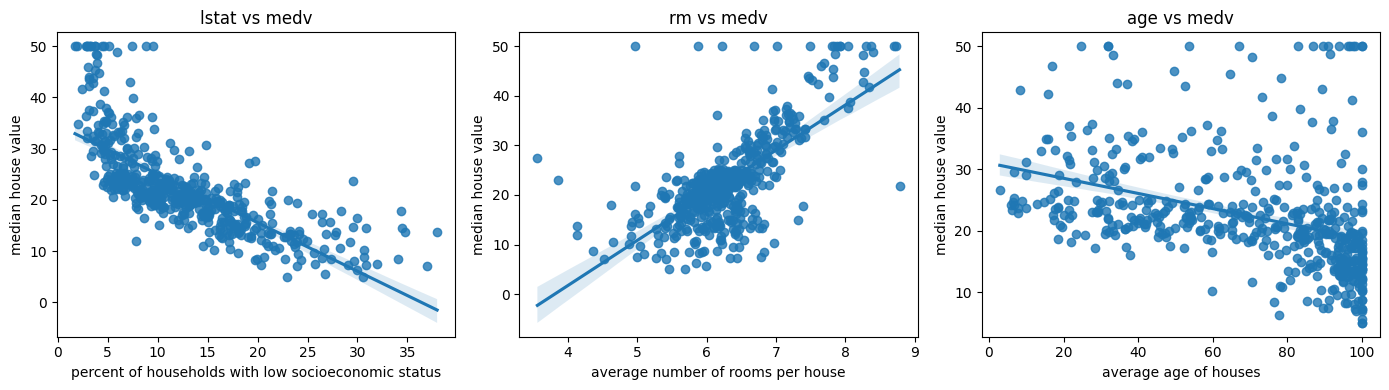

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.regplot(data=Boston, x="lstat", y="medv", ax=axes[0])
axes[0].set_xlabel("percent of households with low socioeconomic status")
axes[0].set_ylabel("median house value")
axes[0].set_title("lstat vs medv")

sns.regplot(data=Boston, x="rm", y="medv", ax=axes[1])
axes[1].set_xlabel("average number of rooms per house")
axes[1].set_ylabel("median house value")
axes[1].set_title("rm vs medv")

sns.regplot(data=Boston, x="age", y="medv", ax=axes[2])
axes[2].set_xlabel("average age of houses")
axes[2].set_ylabel("median house value")
axes[2].set_title("age vs medv")

plt.tight_layout()
plt.show()

In [8]:
X_lstat = sm.add_constant(Boston["lstat"])
lm_lstat = sm.OLS(Boston["medv"], X_lstat).fit()

print("=== medv ~ lstat ===\n")
print(lm_lstat.summary())

=== medv ~ lstat ===

                            OLS Regression Results                            
Dep. Variable:                   medv   R-squared:                       0.544
Model:                            OLS   Adj. R-squared:                  0.543
Method:                 Least Squares   F-statistic:                     601.6
Date:                Mon, 02 Feb 2026   Prob (F-statistic):           5.08e-88
Time:                        00:47:54   Log-Likelihood:                -1641.5
No. Observations:                 506   AIC:                             3287.
Df Residuals:                     504   BIC:                             3295.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         34.5538      0.5

In [9]:
X_rm = sm.add_constant(Boston["rm"])
lm_rm = sm.OLS(Boston["medv"], X_rm).fit()

print("=== medv ~ rm ===\n")
print(lm_rm.summary())

=== medv ~ rm ===

                            OLS Regression Results                            
Dep. Variable:                   medv   R-squared:                       0.484
Model:                            OLS   Adj. R-squared:                  0.483
Method:                 Least Squares   F-statistic:                     471.8
Date:                Mon, 02 Feb 2026   Prob (F-statistic):           2.49e-74
Time:                        00:47:54   Log-Likelihood:                -1673.1
No. Observations:                 506   AIC:                             3350.
Df Residuals:                     504   BIC:                             3359.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -34.6706      2.650 

In [10]:
X_age = sm.add_constant(Boston["age"])
lm_age = sm.OLS(Boston["medv"], X_age).fit()

print("=== medv ~ age ===\n")
print(lm_age.summary())

=== medv ~ age ===

                            OLS Regression Results                            
Dep. Variable:                   medv   R-squared:                       0.142
Model:                            OLS   Adj. R-squared:                  0.140
Method:                 Least Squares   F-statistic:                     83.48
Date:                Mon, 02 Feb 2026   Prob (F-statistic):           1.57e-18
Time:                        00:47:54   Log-Likelihood:                -1801.5
No. Observations:                 506   AIC:                             3607.
Df Residuals:                     504   BIC:                             3615.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         30.9787      0.999

**Interpretation:**  
We fit three separate **simple linear regression** models (medv ~ one predictor). R² measures how much of the variation in median house value is explained by each predictor.  
- **lstat:** When an area has more people with low income, house prices go down. Strong linear relationship (R² = 0.54)—lstat alone explains over half the variance in medv.  
- **rm:** When a home has more rooms, its price tends to be higher. Also strong (R² = 0.48).  
- **age:** Older homes tend to have slightly lower prices. Weaker relationship (R² = 0.14); age alone explains little of the variance.  
All three predictors are statistically significant; the model assumes a linear relationship and minimizes squared errors (OLS).

In [11]:
def format_conf_int(ci):
    df = ci.copy()
    df.columns = ["2.5 %", "97.5 %"]
    df.index = df.index.map(lambda x: "(Intercept)" if x == "const" else x)

    print(df.to_string())

print("medv ~ lstat: 95% CI for coefficients")
format_conf_int(lm_lstat.conf_int(alpha=0.05))

print("\nmedv ~ rm: 95% CI for coefficients")
format_conf_int(lm_rm.conf_int(alpha=0.05))

print("\nmedv ~ age: 95% CI for coefficients")
format_conf_int(lm_age.conf_int(alpha=0.05))

medv ~ lstat: 95% CI for coefficients
                 2.5 %     97.5 %
(Intercept)  33.448457  35.659225
lstat        -1.026148  -0.873951

medv ~ rm: 95% CI for coefficients
                 2.5 %     97.5 %
(Intercept) -39.876641 -29.464601
rm            8.278855   9.925363

medv ~ age: 95% CI for coefficients
                 2.5 %     97.5 %
(Intercept)  29.015752  32.941604
age          -0.149647  -0.096679


**Interpretation:** 

Each interval gives the range of plausible values for the intercept and slope at 95% confidence. For example, for lstat the slope is between about -1.03 and -0.87, so we are confident that a 1-unit increase in lstat is associated with a decrease in medv of roughly 0.9 to 1.0

In [12]:
new_lstat = pd.DataFrame({"const": 1, "lstat": [5, 10, 15]})
pred_lstat = lm_lstat.get_prediction(new_lstat)

sf = pred_lstat.summary_frame(alpha=0.05)
pi = sf[["mean", "obs_ci_lower", "obs_ci_upper"]].copy()
pi.columns = ["fit", "lwr", "upr"]
pi.index = pi.index + 1  # 1-based row names

print("medv ~ lstat: prediction intervals for lstat = 5, 10, 15")
print("A matrix: 3 × 3 of type dbl")
print(pi.to_string())

medv ~ lstat: prediction intervals for lstat = 5, 10, 15
A matrix: 3 × 3 of type dbl
         fit        lwr        upr
1  29.803594  17.565675  42.041513
2  25.053347  12.827626  37.279068
3  20.303101   8.077742  32.528459


In [13]:
new_rm = pd.DataFrame({"const": 1, "rm": [5, 6.5, 8]})
pred_rm = lm_rm.get_prediction(new_rm)

sf = pred_rm.summary_frame(alpha=0.05)
pi = sf[["mean", "obs_ci_lower", "obs_ci_upper"]].copy()
pi.columns = ["fit", "lwr", "upr"]
pi.index = pi.index + 1  # 1-based row names

print("medv ~ rm: prediction intervals for rm = 5, 6.5, 8")
print("A matrix: 3 × 3 of type dbl")
print(pi.to_string())

medv ~ rm: prediction intervals for rm = 5, 6.5, 8
A matrix: 3 × 3 of type dbl
         fit        lwr        upr
1  10.839924  -2.214474  23.894322
2  24.493088  11.480391  37.505784
3  38.146251  25.058353  51.234149


In [14]:
new_age = pd.DataFrame({"const": 1, "age": [25, 50, 75]})
pred_age = lm_age.get_prediction(new_age)

sf = pred_age.summary_frame(alpha=0.05)
pi = sf[["mean", "obs_ci_lower", "obs_ci_upper"]].copy()
pi.columns = ["fit", "lwr", "upr"]
pi.index = pi.index + 1  # 1-based row names

print("medv ~ age: prediction intervals for age = 25, 50, 75")
print("A matrix: 3 × 3 of type dbl")
print(pi.to_string())

medv ~ age: prediction intervals for age = 25, 50, 75
A matrix: 3 × 3 of type dbl
         fit        lwr        upr
1  27.899610  11.090368  44.708852
2  24.820542   8.043748  41.597335
3  21.741474   4.971031  38.511917


**Interpretation:**  

- fit = predicted median house value for that predictor value.  
- lwr and upr = 95% prediction interval: we expect a new house with that predictor vlue to have medv between lwr and upr about 95% of the time
- lstat Lower lstat means bigher predicted value and the intervals are fairly narrow
- rm: More rooms -> higher predicted value; at rm = 5 the interval dips below 0  
- age: Older homes -> slightly lower predicted value; the intervals are wide, so age alone does not pin down price very well

In [15]:
X_multi = sm.add_constant(Boston[["lstat", "rm", "age"]])
lm_multi = sm.OLS(Boston["medv"], X_multi).fit()
print(lm_multi.summary())

                            OLS Regression Results                            
Dep. Variable:                   medv   R-squared:                       0.639
Model:                            OLS   Adj. R-squared:                  0.637
Method:                 Least Squares   F-statistic:                     296.2
Date:                Mon, 02 Feb 2026   Prob (F-statistic):          1.20e-110
Time:                        00:47:54   Log-Likelihood:                -1582.4
No. Observations:                 506   AIC:                             3173.
Df Residuals:                     502   BIC:                             3190.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.1753      3.182     -0.369      0.7

**Interpretation:** 

With all three predictors, R^2 increases to about 0.64, lstat and rm remain highly significant.age becomes non-significant (in case p=0.42), suggesting its efect is largely captured by the other 2 or is collinear with them.

In [16]:
X_all = sm.add_constant(Boston.drop(columns="medv"))
lm_all = sm.OLS(Boston["medv"], X_all).fit()

print(lm_all.summary())

                            OLS Regression Results                            
Dep. Variable:                   medv   R-squared:                       0.741
Model:                            OLS   Adj. R-squared:                  0.734
Method:                 Least Squares   F-statistic:                     108.1
Date:                Mon, 02 Feb 2026   Prob (F-statistic):          6.72e-135
Time:                        00:47:54   Log-Likelihood:                -1498.8
No. Observations:                 506   AIC:                             3026.
Df Residuals:                     492   BIC:                             3085.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         36.4595      5.103      7.144      0.0

**Interpretation:** 

The full model has R^2 = 0.74. Seweral variables (crim, zn, chas, nox, rm, dis, rad, tax, ptratio, black, lstat) clearly matter for price. indus and age do not add much when we already use the others they overlap with other variables, so their effect is already captured.

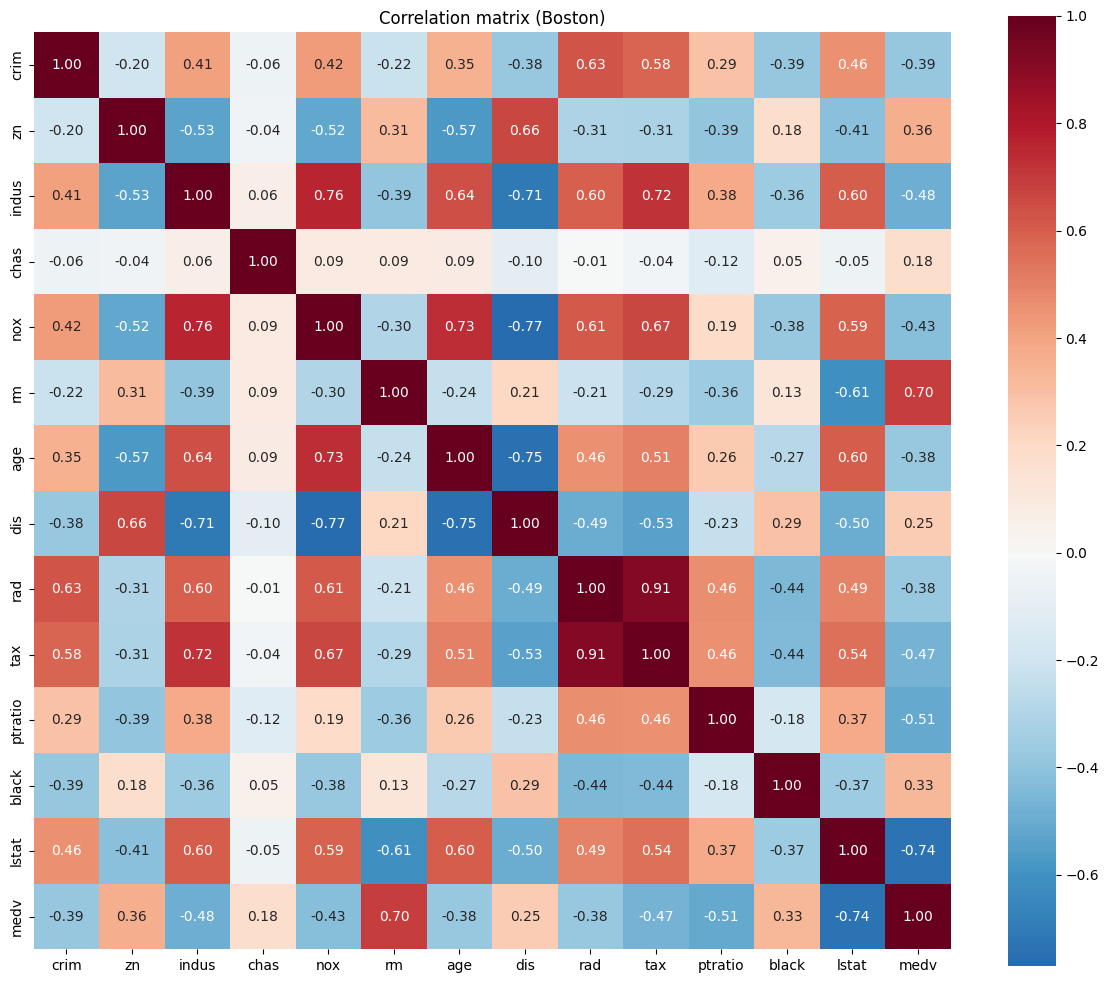

In [17]:
corr = Boston.corr()

plt.figure(figsize=(12, 10))

sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)
plt.title("Correlation matrix (Boston)")

plt.tight_layout()
plt.show()

In [18]:
print("Sample correlations:")
for x in ["lstat", "rm", "age"]:
    r, p = stats.pearsonr(Boston[x], Boston["medv"])
    print(f"  {x} vs medv: r = {r:.4f}, p = {p:.2e}")

Sample correlations:
  lstat vs medv: r = -0.7377, p = 5.08e-88
  rm vs medv: r = 0.6954, p = 2.49e-74
  age vs medv: r = -0.3770, p = 1.57e-18


**Interpretation:** 

Strong correlations among predictors indicate multicollinearity, which can inflate standard errors and make some coefficients unstable. The heatmap helps identify which variables move together.

In [19]:
lstat_vals = [5, 10, 15]
rm_vals = [5, 6.5, 8]

age_median = Boston["age"].median()
selected = pd.DataFrame([
    {"lstat": l, "rm": r, "age": age_median}
    for l in lstat_vals for r in rm_vals
])

selected

,lstat,rm,age
0,5,5.0,77.5
1,5,6.5,77.5
2,5,8.0,77.5
3,10,5.0,77.5
4,10,6.5,77.5
5,10,8.0,77.5
6,15,5.0,77.5
7,15,6.5,77.5
8,15,8.0,77.5


In [20]:
X_new = sm.add_constant(selected[["lstat", "rm", "age"]], has_constant="add")
pred_multi = lm_multi.get_prediction(X_new)

sf = pred_multi.summary_frame(alpha=0.05)
pi = sf[["mean", "obs_ci_lower", "obs_ci_upper"]].copy()
pi.columns = ["fit", "lwr", "upr"]
pi.index = pi.index + 1  # 1-based row names

print("Prediction intervals (medv ~ lstat + rm + age):")
print("A matrix: 9 × 3 of type dbl")
print(pi.to_string())

Prediction intervals (medv ~ lstat + rm + age):
A matrix: 9 × 3 of type dbl
         fit        lwr        upr
1  21.282369  10.226292  32.338445
2  28.811069  17.878278  39.743860
3  36.339769  25.367070  47.312468
4  17.939803   6.949666  28.929940
5  25.468503  14.562642  36.374365
6  32.997204  22.011867  43.982540
7  14.597238   3.647368  25.547108
8  22.125938  11.220895  33.030982
9  29.654638  18.630783  40.678494


In [21]:
coefs = np.round(np.concatenate([[lm_multi.params["const"]], lm_multi.params[["lstat", "rm", "age"]].values]), 4)

print("Coefficients (intercept, lstat, rm, age):", coefs)
print("R²:", lm_multi.rsquared)

Coefficients (intercept, lstat, rm, age): [-1.1753 -0.6685  5.0191  0.0091]
R²: 0.6390341221591789


**Interpretation**:

the analys shows that median house value is best explained by a few key predictors. In simple regression, lstat and number of rooms are the strongest single predictors (R^2 = 0.54 and 0.48) and age alone is weak (R^2= 0.14).

Multiple regression (lstat + rm + age): R^2 rises to about 0.64. lstat and rm stay highly significant with sensible signs that higher lstat goes to lower price and more rooms means higher price. Age becomes nonsignificant once lstat and rm are included, so its effect is largely captured by the other two or is redundant.

Full model : R^2 = 0.74. Several variables (crim, zn, chas, nox, rm, dis, rad, tax, ptratio, black, lstat) are significant. indus and age add little, likely due to overlap with other predictors. The correlation heatmap confirms strong correlations among predictors, which can inflate standard errors and make some coefficients less stable.

Prediction intervals: For the 3-predictor model, the grid of lstat, rm, age shows that predicted medv increases with more rooms and decreases with higher lstat. The 95% prediction intervals give plausible ranges for a new house at each combination; they are wider than confidence intervals because they account for individual observation uncertainty.